In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
model_path = "/content/drive/MyDrive/objectification_model.h5"


In [ ]:
from tensorflow.keras.models import load_model

model = load_model(model_path)
print("Model loaded successfully!")


Model loaded successfully!


In [ ]:
import shutil

# Replace this path with your actual file path in Drive
source_path = "/content/drive/My Drive/frames_cleaned.zip"
destination_path = "/content/frames_cleaned.zip"

shutil.copy(source_path, destination_path)
print("✅ Copied zip from Drive to Colab working directory")


✅ Copied zip from Drive to Colab working directory


In [ ]:
import zipfile

zip_path = "frames_cleaned.zip"
extract_path = "/content/frames_cleaned"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Frames extracted successfully!")

# Verify the structure
!ls /content/frames_cleaned/frames
!ls /content/frames_cleaned/frames/OBJ
!ls /content/frames_cleaned/frames/NON_OBJ

✅ Frames extracted successfully!
NON_OBJ  OBJ
video1	 video15  video20  video27  video32  video38  video43  video49	video54
video10  video16  video21  video28  video33  video39  video44  video5	video55
video11  video17  video22  video29  video34  video4   video45  video50	video6
video12  video18  video23  video3   video35  video40  video46  video51	video7
video13  video19  video25  video30  video36  video41  video47  video52	video8
video14  video2   video26  video31  video37  video42  video48  video53	video9
video1	 video16  video22  video29  video35  video41  video48  video54
video10  video17  video23  video3   video36  video42  video49  video55
video11  video18  video24  video30  video37  video43  video5   video6
video12  video19  video25  video31  video38  video44  video50  video7
video13  video2   video26  video32  video39  video45  video51  video8
video14  video20  video27  video33  video4   video46  video52  video9
video15  video21  video28  video34  video40  video47  video53


In [ ]:
import os
import pandas as pd

# Define the paths
obj_folder = "/content/frames_cleaned/frames/OBJ"
non_obj_folder = "/content/frames_cleaned/frames/NON_OBJ"

# Function to collect frame paths and labels
def collect_frame_data(folder, label):
    frame_data = []
    for video in os.listdir(folder):
        video_path = os.path.join(folder, video)
        if os.path.isdir(video_path):
            for frame in os.listdir(video_path):
                if frame.endswith('.jpg') or frame.endswith('.png'):
                    frame_path = os.path.join(video_path, frame)
                    frame_data.append({
                        'frame_path': frame_path,
                        'label': label
                    })
    return frame_data

# Collect data for OBJ (1) and NON_OBJ (0)
obj_data = collect_frame_data(obj_folder, 1)
non_obj_data = collect_frame_data(non_obj_folder, 0)

# Combine and create DataFrame
all_data = obj_data + non_obj_data
df = pd.DataFrame(all_data)

# Save to CSV
df.to_csv('frames_metadata.csv', index=False)
print("✅ frames_metadata.csv created successfully!")

# Preview the first few rows
print(df.head())

✅ frames_metadata.csv created successfully!
                                          frame_path  label
0  /content/frames_cleaned/frames/OBJ/video18/fra...      1
1  /content/frames_cleaned/frames/OBJ/video18/fra...      1
2  /content/frames_cleaned/frames/OBJ/video18/fra...      1
3  /content/frames_cleaned/frames/OBJ/video28/fra...      1
4  /content/frames_cleaned/frames/OBJ/video28/fra...      1


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import pandas as pd

# Assuming df is your original DataFrame loaded from 'frames_metadata.csv'
# Split into train and test (80% train, 20% test)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# Add a new column 'label_str' with string labels
train_df['label_str'] = train_df['label'].map({0: 'NON_OBJ', 1: 'OBJ'})
test_df['label_str'] = test_df['label'].map({0: 'NON_OBJ', 1: 'OBJ'})

# Define image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Training generator with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

# Test generator (no augmentation, just rescaling)
test_datagen = ImageDataGenerator(rescale=1./255)

# Training generator
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='frame_path',
    y_col='label_str',  # Use the new string label column
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training'
)

# Validation generator
validation_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='frame_path',
    y_col='label_str',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation'
)

# Test generator
test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='frame_path',
    y_col='label_str',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

print("✅ Data generators created!")

Found 2948 validated image filenames belonging to 2 classes.
Found 736 validated image filenames belonging to 2 classes.
Found 922 validated image filenames belonging to 2 classes.
✅ Data generators created!


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
# Reload and test again with shuffle=False
test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='frame_path',
    y_col='label_str',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


Found 922 validated image filenames belonging to 2 classes.


In [ ]:


# Get predicted probabilities
pred_probs = model.predict(test_generator, verbose=1)

# Convert to binary labels
y_pred = (pred_probs > 0.5).astype(int).flatten()

# True labels
y_true = test_generator.classes


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


29/29 ━━━━━━━━━━━━━━━━━━━━ 12s 255ms/step


In [ ]:
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=["NON_OBJ", "OBJ"]))

print("✅ Accuracy:  {:.2f}%".format(accuracy_score(y_true, y_pred) * 100))
print("✅ Precision: {:.2f}".format(precision_score(y_true, y_pred)))
print("✅ Recall:    {:.2f}".format(recall_score(y_true, y_pred)))
print("✅ F1 Score:  {:.2f}".format(f1_score(y_true, y_pred)))


Classification Report:
              precision    recall  f1-score   support

     NON_OBJ       0.94      0.89      0.92       606
         OBJ       0.81      0.90      0.85       316

    accuracy                           0.89       922
   macro avg       0.88      0.89      0.88       922
weighted avg       0.90      0.89      0.89       922

✅ Accuracy:  89.26%
✅ Precision: 0.81
✅ Recall:    0.90
✅ F1 Score:  0.85


In [ ]:
print(test_generator.class_indices)


{'NON_OBJ': 0, 'OBJ': 1}


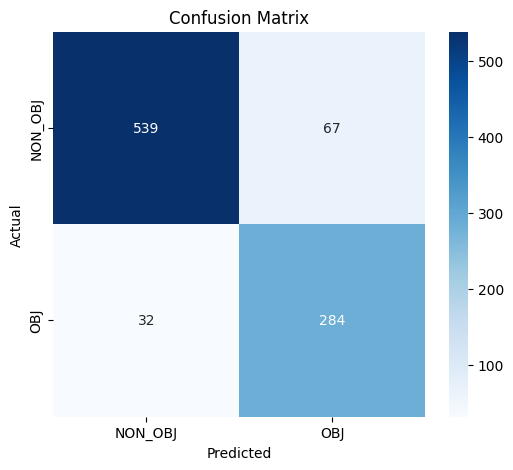

In [ ]:
cm = confusion_matrix(y_true, y_pred)
labels = ["NON_OBJ", "OBJ"]

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 157ms/step


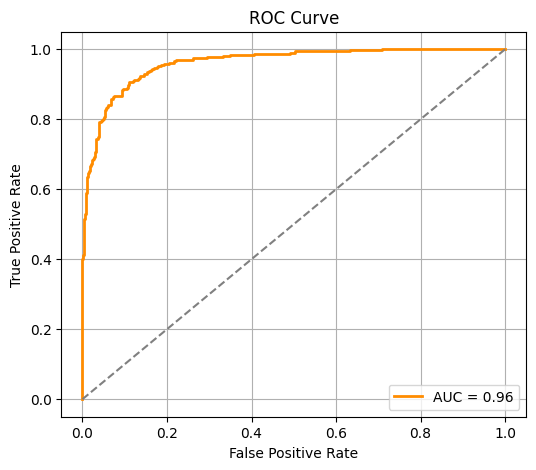

In [ ]:
from sklearn.metrics import roc_curve, auc

# Get prediction probabilities
y_scores = model.predict(test_generator).ravel()
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# Plot ROC
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()


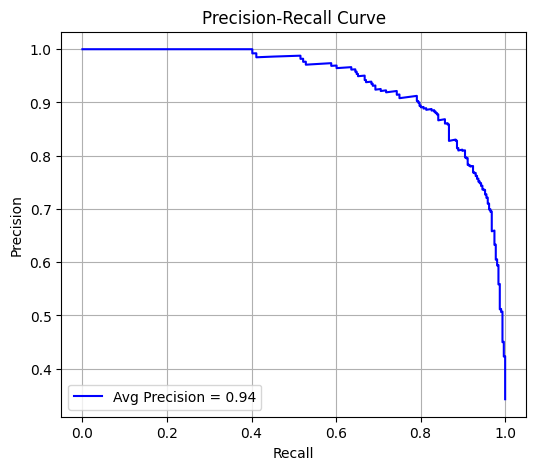

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(y_true, y_scores)
avg_prec = average_precision_score(y_true, y_scores)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, color='blue', label=f'Avg Precision = {avg_prec:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()


GRADCAM

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model
import cv2

def get_gradcam(img_path, model, last_conv_layer_name='Conv_1', preprocess_input_fn=None):
    # Load image
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0  # Rescale (since you used rescaling in ImageDataGenerator)

    # Create a model that maps input image to the activations and prediction
    grad_model = Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Compute the gradient of the top predicted class for that image
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0].numpy()
    pooled_grads = pooled_grads.numpy()

    # Weight the channels by the importance
    for i in range(pooled_grads.shape[-1]):
        conv_outputs[:, :, i] *= pooled_grads[i]

    heatmap = np.mean(conv_outputs, axis=-1)

    # Normalize heatmap
    heatmap = np.maximum(heatmap, 0)
    heatmap /= np.max(heatmap)

    # Resize and overlay
    img_orig = cv2.imread(img_path)
    img_orig = cv2.resize(img_orig, (224, 224))
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_resized = np.uint8(255 * heatmap_resized)
    heatmap_colored = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(img_orig, 0.6, heatmap_colored, 0.4, 0)

    return superimposed_img, heatmap


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


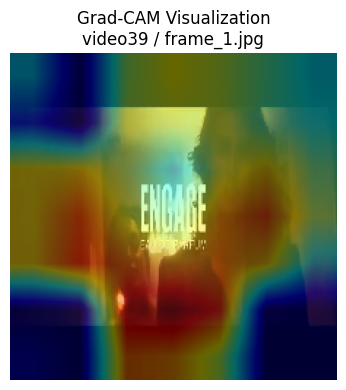

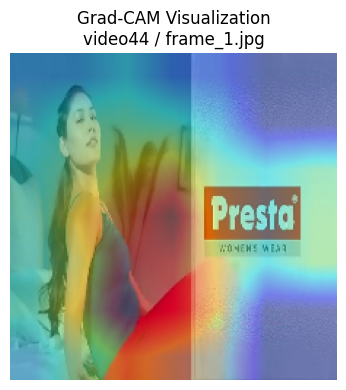

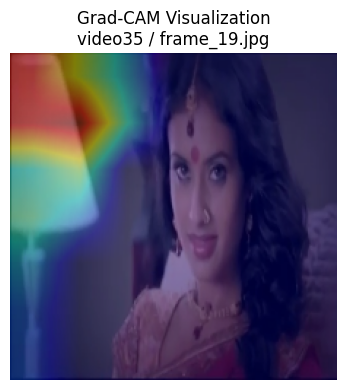

In [ ]:
import random

# Pick random OBJ image from test set
obj_test_df = test_df[test_df['label'] == 1]
sample_paths = obj_test_df.sample(3)['frame_path'].tolist()

# Plot Grad-CAM
for i, path in enumerate(sample_paths):
    cam, _ = get_gradcam(path, model)
    plt.figure(figsize=(4, 4))
    plt.imshow(cv2.cvtColor(cam, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title(f"Grad-CAM Visualization\n{path.split('/')[-2]} / {path.split('/')[-1]}")
    plt.tight_layout()
    plt.show()


LIME

In [ ]:
!pip install lime


In [ ]:
sample_paths = [
    '/content/frames_cleaned/frames/OBJ/video39/frame_1.jpg',
    '/content/frames_cleaned/frames/OBJ/video44/frame_1.jpg',
    '/content/frames_cleaned/frames/OBJ/video35/frame_19.jpg'
]


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━

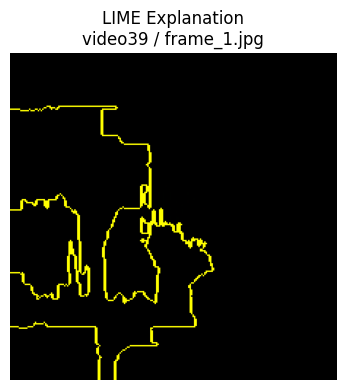

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━

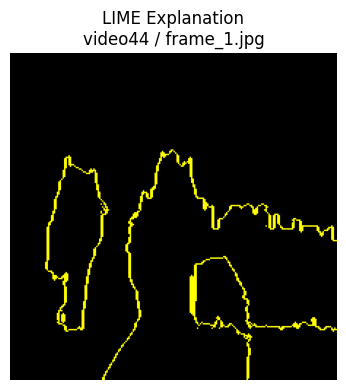

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━

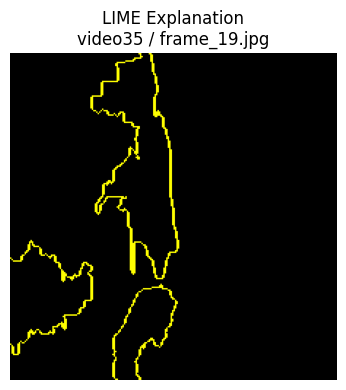

In [ ]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

explainer = lime_image.LimeImageExplainer()

# Helper to preprocess and predict
def predict_fn(images):
    images = np.array(images)
    return model.predict(images)

# Run LIME on each image
for img_path in sample_paths:
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    explanation = explainer.explain_instance(
        img_array.astype('double'),
        predict_fn,
        top_labels=1,
        hide_color=0,
        num_samples=1000
    )

    # Show LIME explanation
    temp, mask = explanation.get_image_and_mask(
        label=explanation.top_labels[0],
        positive_only=True,
        hide_rest=False
    )

    plt.figure(figsize=(4, 4))
    plt.imshow(mark_boundaries(temp / 255.0, mask))
    plt.axis('off')
    plt.title(f"LIME Explanation\n{img_path.split('/')[-2]} / {img_path.split('/')[-1]}")
    plt.tight_layout()
    plt.show()


In [ ]:
from lime import lime_image
from skimage.segmentation import mark_boundaries
from tensorflow.keras.preprocessing import image
import numpy as np

explainer = lime_image.LimeImageExplainer()

lime_explanations = []

for img_path in sample_paths:
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    explanation = explainer.explain_instance(
        img_array.astype('double'),
        classifier_fn=model.predict,
        top_labels=1,
        hide_color=0,
        num_samples=1000
    )
    lime_explanations.append((img_path, explanation))


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━

In [ ]:
gradcam_images = []

for img_path in sample_paths:
    grad_img, _ = get_gradcam(img_path, model)
    gradcam_images.append((img_path, grad_img))


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

def plot_comparisons(image_paths, gradcam_data, lime_data):
    for i in range(len(image_paths)):
        img_path = image_paths[i]
        grad_img = gradcam_data[i][1]
        lime_expl = lime_data[i][1]
        lime_label = lime_expl.top_labels[0]

        # Load original image
        orig_img = image.load_img(img_path, target_size=(224, 224))

        # LIME mask
        lime_img, lime_mask = lime_expl.get_image_and_mask(
            label=lime_label,
            positive_only=True,
            hide_rest=False
        )

        # Plot all three
        fig, axes = plt.subplots(1, 3, figsize=(12, 4))

        axes[0].imshow(orig_img)
        axes[0].set_title("Original")
        axes[0].axis("off")

        axes[1].imshow(cv2.cvtColor(grad_img, cv2.COLOR_BGR2RGB))
        axes[1].set_title("Grad-CAM")
        axes[1].axis("off")

        axes[2].imshow(mark_boundaries(lime_img / 255.0, lime_mask))
        axes[2].set_title("LIME")
        axes[2].axis("off")

        plt.suptitle(img_path.split("/")[-2] + " / " + img_path.split("/")[-1], fontsize=14)
        plt.tight_layout()
        plt.show()


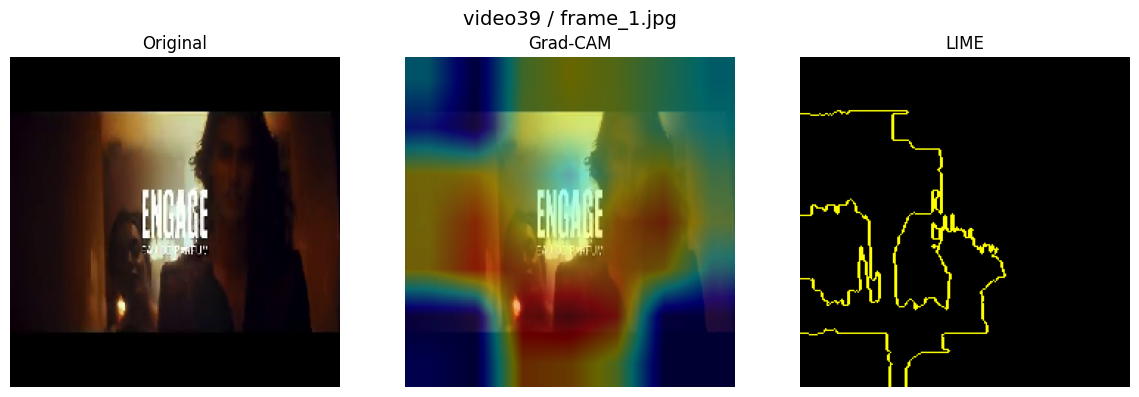

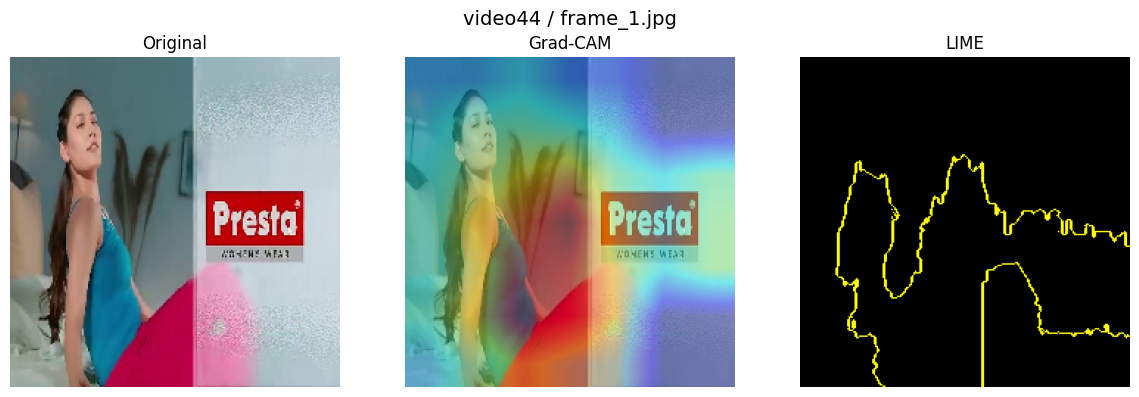

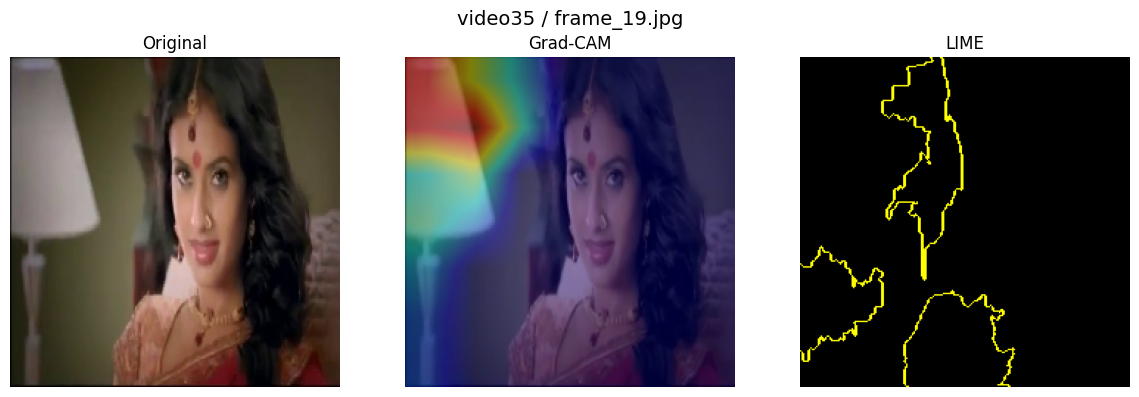

In [ ]:
plot_comparisons(sample_paths, gradcam_images, lime_explanations)
